Initial Positions

Using alpha = 100000.0  (13000 rows)


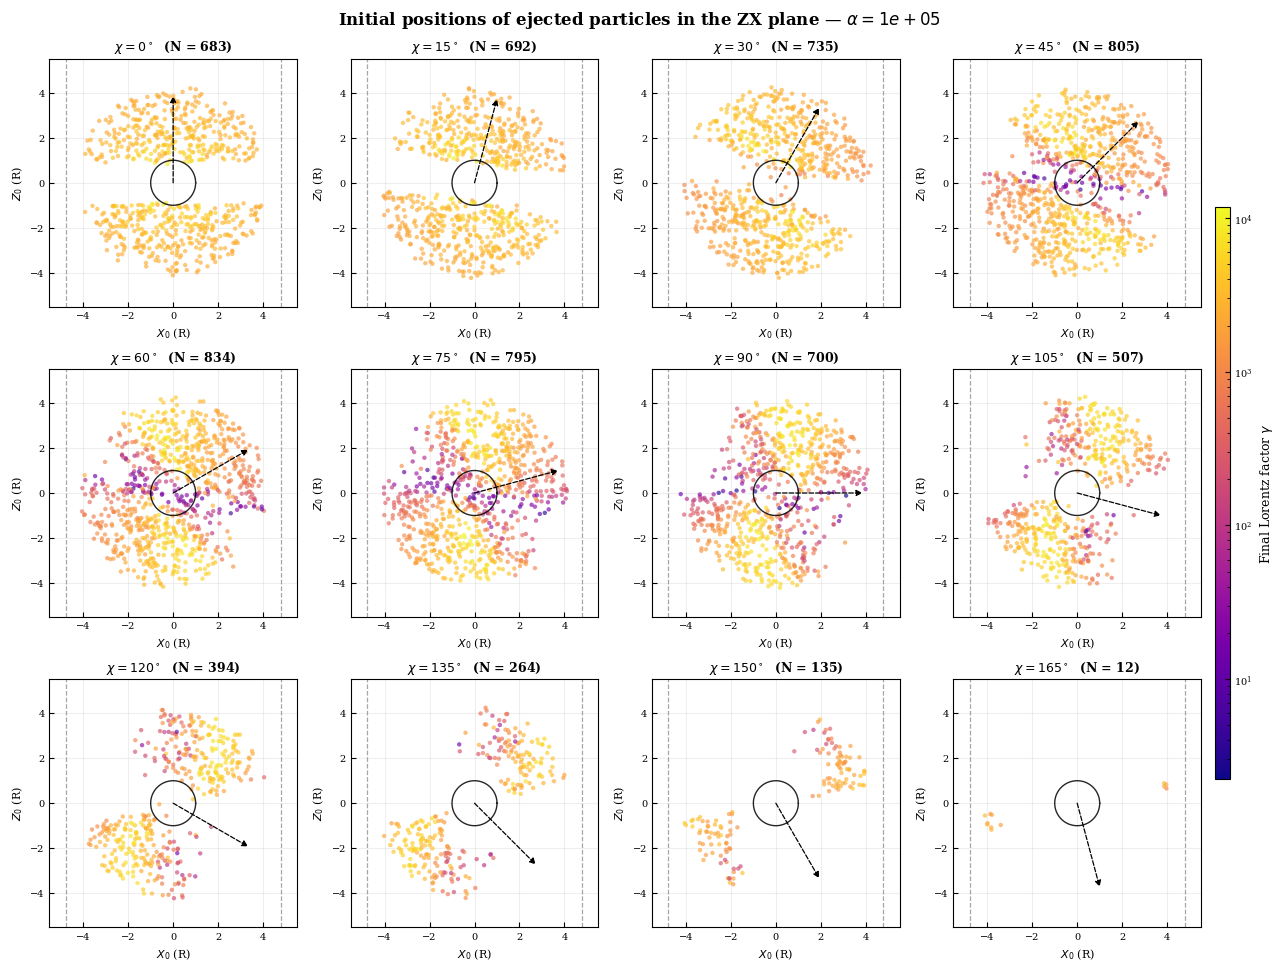

Salvo: initial_positions_alpha1e+05.pdf


In [19]:
# ==========================================
# BLOCK 1 — GRADE 3×4 — POSIÇÕES INICIAIS (ZX)
# Fonte única: particles_all_runs.csv
# ==========================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e5              # qual alpha plotar

ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

POINT_SIZE  = 10
POINT_ALPHA = 0.65
CMAP        = 'plasma'
MARKER_EDGE = 'none'

om       = 0.209
r_lc_val = 1.0 / om

# ==========================================
# CARREGA E FILTRA
# ==========================================
if not os.path.isfile(CSV_FILE):
    raise FileNotFoundError(f"{CSV_FILE} not found.")

df_all = pd.read_csv(CSV_FILE)

# Verifica se o alpha pedido existe
alphas_avail = sorted(df_all["alpha"].unique())
if ALPHA_VAL not in alphas_avail:
    print(f"[WARN] alpha={ALPHA_VAL} not in CSV. Available: {alphas_avail}")
    print(f"       Plotting closest available instead.")
    ALPHA_VAL = float(alphas_avail[np.argmin(np.abs(np.array(alphas_avail) - ALPHA_VAL))])
    print(f"       Using alpha = {ALPHA_VAL}")

df = df_all[df_all["alpha"] == ALPHA_VAL].copy()
print(f"Using alpha = {ALPHA_VAL}  ({len(df)} rows)")

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS, N_COLS = 3, 4
fig, axes = plt.subplots(N_ROWS, N_COLS,
                         figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                         constrained_layout=True)
axes = axes.ravel()

theta_circ = np.linspace(0, 2*np.pi, 400)
ZOOM_LIM   = r_lc_val * 1.15

d_all = df[df.status == "Ejected"]
if len(d_all):
    vmin = max(d_all.gamma.min(), 1.0)
    vmax = max(d_all.gamma.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d  = df[(df.angle_deg == ang) & (df.status == "Ejected")]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes, fontsize=8)
        ax.set_axis_off()
        continue

    x0, z0, gamas = d.x0.values, d.z0.values, d.gamma.values
    N = len(gamas)

    ax.scatter(x0, z0, c=gamas, cmap=CMAP,
               norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='black', lw=1.0, alpha=0.85, zorder=4)

    ax.axvline( r_lc_val, color='gray', ls='--', lw=0.9, alpha=0.7, zorder=2)
    ax.axvline(-r_lc_val, color='gray', ls='--', lw=0.9, alpha=0.7, zorder=2)

    chi_rad = np.radians(ang)
    L_dip = ZOOM_LIM * 0.7
    arrow = FancyArrowPatch((0, 0),
                            (np.sin(chi_rad) * L_dip,
                             np.cos(chi_rad) * L_dip),
                            arrowstyle='-|>', color='black',
                            lw=0.9, linestyle='--', mutation_scale=9,
                            shrinkA=0, shrinkB=0, zorder=5)
    ax.add_patch(arrow)

    ax.set_xlabel(r'$X_0$ (R)', fontsize=8)
    ax.set_ylabel(r'$Z_0$ (R)', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {N})',
                 fontweight='bold', fontsize=9)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2, zorder=0)
    ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
    ax.tick_params(labelsize=7)

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Initial positions of ejected particles in the ZX plane — '
             rf'$\alpha = {ALPHA_VAL:.0e}$',
             fontsize=12, fontweight='bold')

out = f'initial_positions_alpha{ALPHA_VAL:.0e}.pdf'
plt.savefig(out, dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

Final Positions

In [ ]:
# ==========================================
# BLOCK 2 — GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE (XZ)
# Fonte única: particles_all_runs.csv
# ==========================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e5

ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

POINT_SIZE  = 8
POINT_ALPHA = 0.65
CMAP        = 'plasma'
MARKER_EDGE = 'none'

# ---------- Carrega ----------
if not os.path.isfile(CSV_FILE):
    raise FileNotFoundError(f"{CSV_FILE} not found.")

df_all = pd.read_csv(CSV_FILE)
alphas_avail = sorted(df_all["alpha"].unique())
if ALPHA_VAL not in alphas_avail:
    print(f"[WARN] alpha={ALPHA_VAL} not in CSV. Using closest.")
    ALPHA_VAL = float(alphas_avail[np.argmin(np.abs(np.array(alphas_avail) - ALPHA_VAL))])

df = df_all[df_all["alpha"] == ALPHA_VAL].copy()
df_ej = df[df.status == "Ejected"].copy()
print(f"Using alpha = {ALPHA_VAL}  ({len(df_ej)} ejected)")

if len(df_ej):
    vmin = max(df_ej.gamma.min(), 1.0)
    vmax = max(df_ej.gamma.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

# ---------- Layout 3×4 ----------
N_ROWS, N_COLS = 3, 4
fig, axes = plt.subplots(N_ROWS, N_COLS,
                         figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                         constrained_layout=True)
axes = axes.ravel()

r_esc  = 3.0 / 0.209
R_norm = 1.0 / r_esc
theta_circ = np.linspace(0, 2*np.pi, 400)

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_ej[df_ej.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes, fontsize=8)
        ax.set_axis_off()
        continue

    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = d.xf / r_norm
    zf_n = d.zf / r_norm

    ax.scatter(xf_n, zf_n,
               c=d.gamma.values,
               cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    ax.add_patch(plt.Circle((0, 0), R_norm, color='black',
                            zorder=5, alpha=0.95))

    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)

    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = {ALPHA_VAL:.0e}$',
             fontsize=12, fontweight='bold')

out = f'escape_directions_alpha{ALPHA_VAL:.0e}.pdf'
plt.savefig(out, dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

Spectra

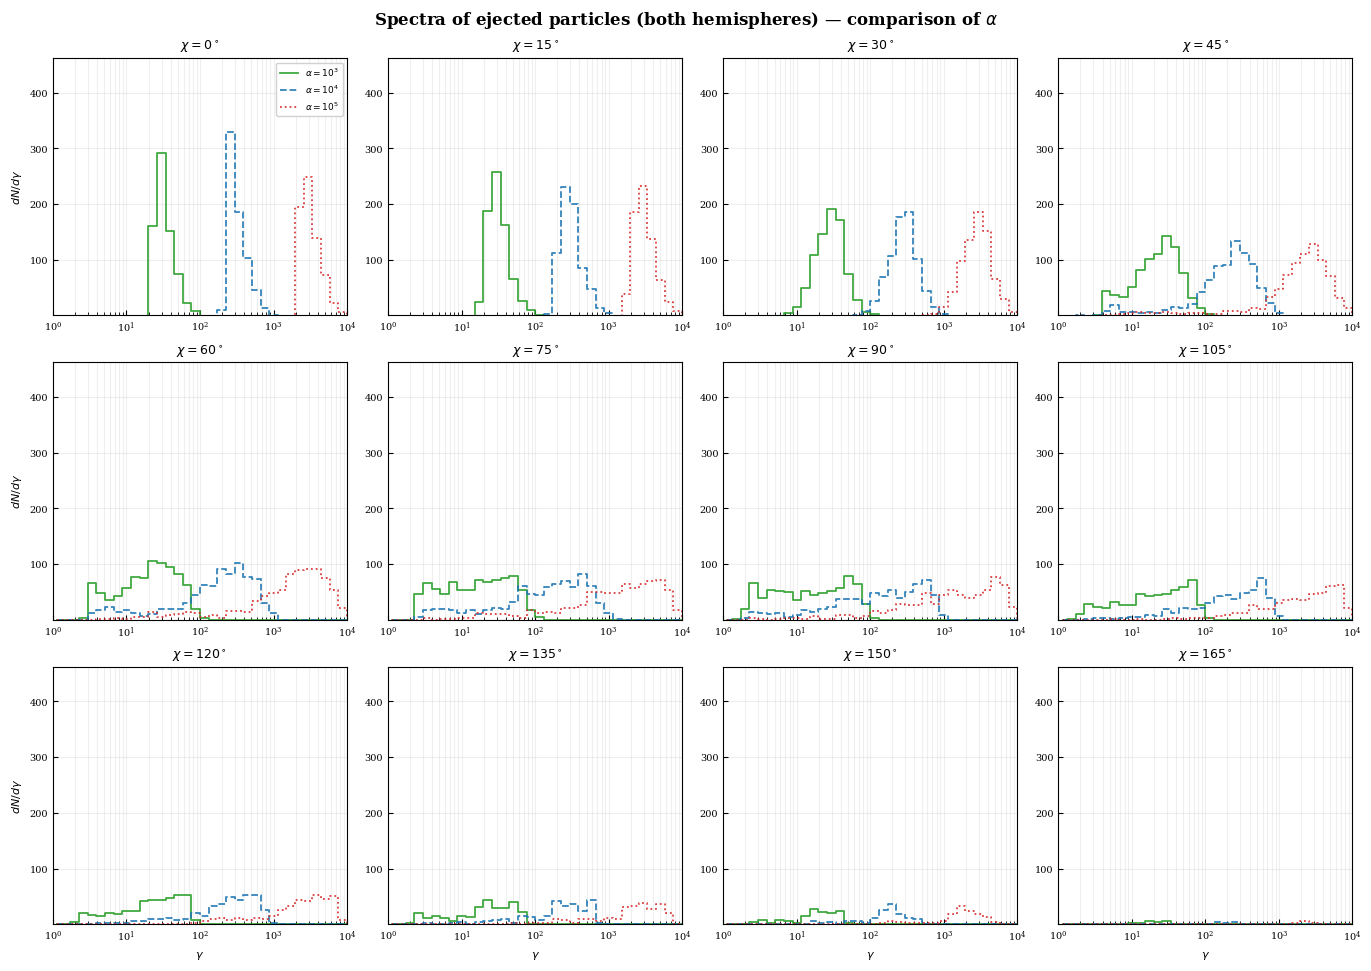

Salvo: spectra_compare_alphas_both.pdf


In [18]:
# ==========================================
# BLOCK 3 (multi-α) — GRADE 3×4 — ESPECTROS
# Fonte única: particles_all_runs.csv
# Escolha quantos alphas quiser na lista ALPHAS_TO_PLOT
# ==========================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO — EDITE AQUI
# ==========================================
CSV_FILE = "particles_all_runs.csv"

# Quantos alphas quiser — basta listar:
ALPHAS_TO_PLOT = [1e3,1e4,1e5]

HEMISPHERE = "both"          # "N", "S", "both"
ANGLES     = [0, 15, 30, 45, 60, 75,
              90, 105, 120, 135, 150, 165]

N_BINS     = 40
G_LO, G_HI = 1.0, 50000

# Paleta automática — usa quantas cores forem necessárias
_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown',
               'tab:pink', 'tab:olive', 'tab:cyan',
               'magenta', 'navy', 'darkred']

# Estilos de linha — cicla automaticamente
_LS_POOL = ['-', '--', ':', '-.']

# ==========================================
# CARREGA
# ==========================================
if not os.path.isfile(CSV_FILE):
    raise FileNotFoundError(f"{CSV_FILE} not found.")

df_all = pd.read_csv(CSV_FILE)
alphas_avail = sorted(df_all["alpha"].unique())

# Filtra apenas os alphas pedidos que existem
ALPHAS = [a for a in ALPHAS_TO_PLOT if a in alphas_avail]
missing = [a for a in ALPHAS_TO_PLOT if a not in alphas_avail]
if missing:
    print(f"[WARN] alphas not in CSV: {missing}")
    print(f"       Available: {alphas_avail}")
if not ALPHAS:
    raise ValueError("None of the requested alphas are in the CSV.")

# Mapa de cor e estilo
COLORS = {a: _COLOR_POOL[i % len(_COLOR_POOL)]
          for i, a in enumerate(ALPHAS)}
STYLES = {a: _LS_POOL[i % len(_LS_POOL)]
          for i, a in enumerate(ALPHAS)}

def alpha_label(a):
    exp = int(round(np.log10(a)))
    if 10**exp == a:
        return rf"$\alpha = 10^{{{exp}}}$"
    return rf"$\alpha = {a:g}$"

LABELS = {a: alpha_label(a) for a in ALPHAS}

# ==========================================
# FILTRA HEMISFÉRIO E STATUS
# ==========================================
df = df_all[df_all["alpha"].isin(ALPHAS)].copy()
if HEMISPHERE == "N":
    df = df[df.z0 > 0]
elif HEMISPHERE == "S":
    df = df[df.z0 < 0]
df_ej = df[df.status == "Ejected"]

# ==========================================
# BINS COMUNS (log)
# ==========================================
LOG_EDGES = np.linspace(np.log10(G_LO), np.log10(G_HI), N_BINS + 1)
G_CENTERS = 10 ** (0.5 * (LOG_EDGES[:-1] + LOG_EDGES[1:]))

# ==========================================
# HISTOGRAMAS
# ==========================================
hists = {a: {} for a in ALPHAS}
for a in ALPHAS:
    d_a = df_ej[df_ej.alpha == a]
    for ang in ANGLES:
        dd = d_a[d_a.angle_deg == ang]
        g = dd.gamma.values
        g_in = g[(g >= G_LO) & (g <= G_HI)]
        if len(g_in) == 0:
            hists[a][ang] = None
            continue
        hist, _ = np.histogram(np.log10(np.clip(g_in, 1.0, None)),
                               bins=LOG_EDGES)
        hists[a][ang] = hist

# ==========================================
# YLIM COMUM
# ==========================================
all_max = 1.0
for a in ALPHAS:
    for h in hists[a].values():
        if h is not None and h.max() > all_max:
            all_max = h.max()
Y_LO = 0.5
Y_HI = max(2.0, all_max * 1.4)

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS, N_COLS = 3, 4
fig, axes = plt.subplots(N_ROWS, N_COLS,
                         figsize=(3.4 * N_COLS, 3.2 * N_ROWS),
                         constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    has_any = False
    for a in ALPHAS:
        h = hists[a].get(ang)
        if h is None:
            continue
        has_any = True
        ax.step(G_CENTERS, h, where='mid',
                color=COLORS[a], ls=STYLES[a],
                lw=1.3, alpha=0.9,
                label=LABELS[a])

    if not has_any:
        ax.text(0.5, 0.5, "No particles were ejected", ha='center', va='center',
                transform=ax.transAxes, fontsize=8, color='black')
        ax.set_axis_off()
        continue

    ax.set_xscale('log')
    ax.set_xlim(1, 10000)
    ax.set_ylim(Y_LO, Y_HI)
    ax.set_title(rf'$\chi = {ang}^\circ$',
                 fontweight='bold', fontsize=9)

    if idx % N_COLS == 0:
        ax.set_ylabel(r'$dN/d\gamma$', fontsize=8)
    if idx >= (N_ROWS - 1) * N_COLS:
        ax.set_xlabel(r'$\gamma$', fontsize=8)

    ax.grid(True, alpha=0.2, which='both')
    ax.tick_params(labelsize=7)

    if idx == 0:
        ax.legend(loc='upper right', fontsize=6.5, framealpha=0.9)

hemi_label = {"N": "northern hemisphere",
              "S": "southern hemisphere",
              "both": "both hemispheres"}[HEMISPHERE]

fig.suptitle(rf'Spectra of ejected particles ({hemi_label}) — '
             rf'comparison of $\alpha$',
             fontsize=12, fontweight='bold')

out = f'spectra_compare_alphas_{HEMISPHERE}.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

In [7]:
# =========================================================
# SPECTRA DIAGNOSTIC TABLE
# For each (alpha, angle), list key statistics of the ejected
# particle gamma distribution. Feeds the results-text rewrite.
# =========================================================
import numpy as np
import pandas as pd

CSV_FILE = "particles_all_runs.csv"

# Which alphas to include in the table
ALPHAS_TO_TABLE = [1e3, 1e4]

# Which hemisphere: "N" (z0 > 0), "S" (z0 < 0), "both"
HEMISPHERE = "both"

df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

# Apply hemisphere filter
if HEMISPHERE == "N":
    df = df[df.z0 > 0]
elif HEMISPHERE == "S":
    df = df[df.z0 < 0]

df_ej = df[df.status == "Ejected"]

alphas_avail = sorted(df["alpha"].unique())
angles_avail = sorted(df["angle_deg"].unique())

print("=" * 130)
print(f"SPECTRA DIAGNOSTIC — hemisphere = {HEMISPHERE}")
print("=" * 130)

# ---------------------------------------------------------
# 1) Summary table: N, gamma stats, bimodality flag
# ---------------------------------------------------------
rows = []
for a in ALPHAS_TO_TABLE:
    if a not in alphas_avail:
        continue
    for ang in angles_avail:
        d = df_ej[(df_ej.alpha == a) & (df_ej.angle_deg == ang)]
        N = len(d)
        if N < 10:
            rows.append({
                "alpha": a, "chi": ang, "N": N,
                "g_min": np.nan, "g_med": np.nan,
                "g_mean": np.nan, "g_max": np.nan,
                "std_logg": np.nan,
                "log_range": np.nan,
                "bimodal": ""
            })
            continue
        g = d.gamma_final.values
        logg = np.log10(np.clip(g, 1.0, None))
        g_min  = g.min()
        g_med  = np.median(g)
        g_mean = g.mean()
        g_max  = g.max()
        std_logg = logg.std()
        log_range = logg.max() - logg.min()

        # Simple bimodality test: gap statistic on log10(gamma)
        # Look for a gap in the middle 60% of the distribution
        gs = np.sort(logg)
        n = len(gs)
        lo = int(0.2 * n)
        hi = int(0.8 * n)
        if hi - lo > 3:
            diffs = np.diff(gs[lo:hi])
            max_gap = diffs.max() if len(diffs) else 0.0
        else:
            max_gap = 0.0
        bimodal = "YES" if max_gap > 0.5 else ""

        rows.append({
            "alpha": a, "chi": ang, "N": N,
            "g_min": g_min, "g_med": g_med,
            "g_mean": g_mean, "g_max": g_max,
            "std_logg": std_logg,
            "log_range": log_range,
            "bimodal": bimodal,
        })

table = pd.DataFrame(rows)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', '{:.2f}'.format)

for a in ALPHAS_TO_TABLE:
    sub = table[table.alpha == a]
    if len(sub) == 0:
        continue
    print(f"\n--- alpha = {a:.0e} ---")
    print(sub.to_string(index=False))

# ---------------------------------------------------------
# 2) Scale-invariance check: ratio of median gammas
# ---------------------------------------------------------
print("\n" + "=" * 130)
print("SCALE INVARIANCE — median gamma ratio between alpha values")
print("=" * 130)

for a_lo, a_hi in [(1e3, 1e4), (1e4, 1e5)]:
    if a_lo not in alphas_avail or a_hi not in alphas_avail:
        continue
    print(f"\nalpha_hi / alpha_lo = {a_hi:.0e} / {a_lo:.0e} = "
          f"{a_hi/a_lo:.1f}")
    print(f"{'chi':>5}  {'med_lo':>9}  {'med_hi':>9}  "
          f"{'ratio':>8}  {'expected':>9}")
    for ang in angles_avail:
        dlo = df_ej[(df_ej.alpha == a_lo)
                    & (df_ej.angle_deg == ang)]
        dhi = df_ej[(df_ej.alpha == a_hi)
                    & (df_ej.angle_deg == ang)]
        if len(dlo) < 5 or len(dhi) < 5:
            continue
        m_lo = np.median(dlo.gamma_final)
        m_hi = np.median(dhi.gamma_final)
        ratio = m_hi / max(m_lo, 1e-9)
        expected = a_hi / a_lo
        print(f"{ang:>5}  {m_lo:>9.2f}  {m_hi:>9.2f}  "
              f"{ratio:>8.3f}  {expected:>9.1f}")

# ---------------------------------------------------------
# 3) Bimodality check by hemisphere at intermediate angles
# ---------------------------------------------------------
print("\n" + "=" * 130)
print("BIMODALITY CHECK by hemisphere at intermediate angles")
print("=" * 130)

for a in ALPHAS_TO_TABLE:
    if a not in alphas_avail:
        continue
    for ang in [30, 45, 60, 75, 90]:
        if ang not in angles_avail:
            continue
        for hemi, mask in [("N", df_ej.z0 > 0),
                            ("S", df_ej.z0 < 0)]:
            d = df_ej[(df_ej.alpha == a)
                      & (df_ej.angle_deg == ang)
                      & mask]
            if len(d) < 5:
                continue
            g = np.log10(np.clip(d.gamma_final.values, 1.0, None))
            gs = np.sort(g)
            n = len(gs)
            lo, hi = int(0.2*n), int(0.8*n)
            if hi - lo > 3:
                gap = np.diff(gs[lo:hi]).max()
            else:
                gap = 0.0
            flag = "BIMODAL" if gap > 0.5 else ""
            print(f"  alpha={a:.0e}  chi={ang:>3}  "
                  f"hemi={hemi}  N={len(d):>4}  "
                  f"med={10**np.median(g):>8.2f}  "
                  f"gap={gap:.2f}  {flag}")

SPECTRA DIAGNOSTIC — hemisphere = both

--- alpha = 1e+03 ---
  alpha  chi   N  g_min  g_med  g_mean  g_max  std_logg  log_range bimodal
1000.00    0 708  22.30  30.24   33.97  91.25      0.12       0.61        
1000.00   15 736  17.97  30.04   33.24 106.11      0.14       0.77        
1000.00   30 799   7.11  28.46   30.81 108.90      0.19       1.19        
1000.00   45 853   3.84  23.64   26.67 112.37      0.31       1.47        
1000.00   60 880   2.78  20.75   26.25 113.89      0.40       1.61        
1000.00   75 832   2.40  16.85   24.05 117.62      0.45       1.69        
1000.00   90 744   1.53  15.59   25.35 111.94      0.50       1.86        
1000.00  105 565   1.47  22.51   30.03 112.06      0.47       1.88        
1000.00  120 431   1.83  23.42   29.19  88.88      0.43       1.69        
1000.00  135 293   1.59  21.41   25.70  71.87      0.43       1.65        
1000.00  150 140   2.17  19.49   20.80  47.84      0.33       1.34        
1000.00  165  20   8.41  17.86   18.87

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

CSV_FILE = "particles_all_runs.csv"
df = pd.read_csv(CSV_FILE)

# Normalize: accept either `gamma` or `gamma_final`
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})

# Make sure angle_deg is integer (CSVs may carry floats)
df["angle_deg"] = df["angle_deg"].round().astype(int)

ALL_ANGLES = sorted(df["angle_deg"].unique())
ALL_ALPHAS = sorted(df["alpha"].unique())

print("angles:", ALL_ANGLES)
print("alphas:", ALL_ALPHAS)

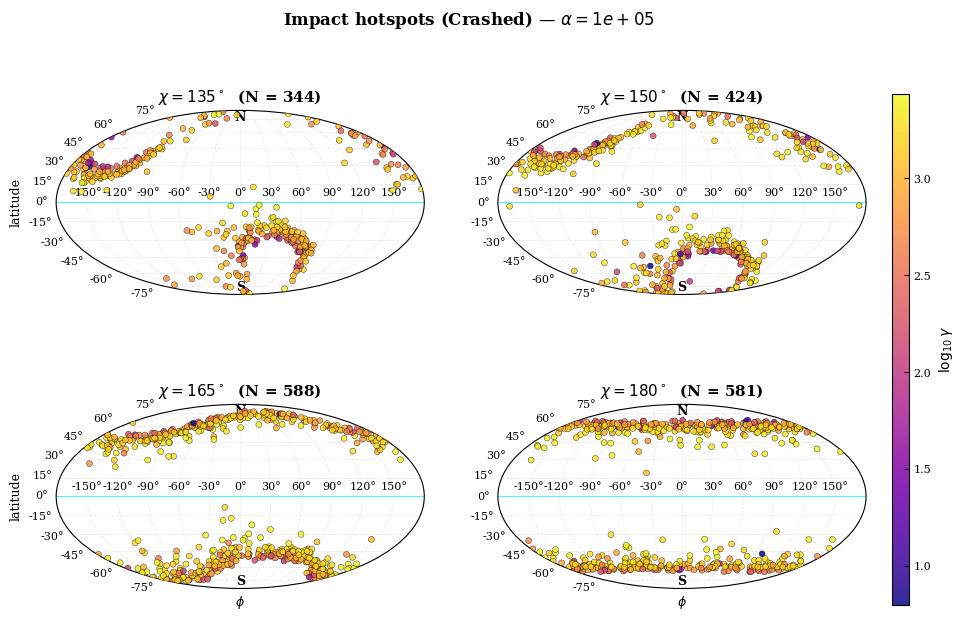

Salvo: hotspots_mollweide_Crashed_alpha1e+05.pdf


In [20]:
# =========================================================
# FIGURE 1 — HOTSPOTS 2D — projeção Mollweide — grade 2×2
# Configurável: alpha, status, quatro ângulos
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e5
STATUS    = "Crashed"          # "Crashed", "Ejected" ou "Trapped"
ANGLES    = [135, 150, 165, 180]   # exatamente 4, na ordem desejada

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

# ---------- Layout 2×2 ----------
fig, axes = plt.subplots(2, 2, figsize=(11, 7),
                          subplot_kw=dict(projection='mollweide'))
axes = axes.ravel()

sc_last = None
for k, ang in enumerate(ANGLES):
    ax = axes[k]
    d = df[(df.angle_deg == ang) &
           (df.alpha == ALPHA_VAL) &
           (df.status == STATUS)].copy()

    if len(d) == 0:
        ax.text(0, 0, f'No {STATUS}', ha='center', va='center')
        ax.set_title(rf'$\chi = {ang}^\circ$  (N = 0)',
                     fontweight='bold', fontsize=11)
        continue

    xf, yf, zf = d.xf.values, d.yf.values, d.zf.values
    r = np.sqrt(xf**2 + yf**2 + zf**2)
    theta_f = np.arccos(np.clip(zf/r, -1, 1))
    phi_f   = np.arctan2(yf, xf)
    lon = phi_f
    lat = np.pi/2 - theta_f

    gamma      = d.gamma_final.values
    log_gamma  = np.log10(np.clip(gamma, 1, None))

    sc = ax.scatter(lon, lat,
                    c=log_gamma, cmap='plasma',
                    s=18, alpha=0.85,
                    edgecolors='black', linewidths=0.3,
                    vmin=log_gamma.min(), vmax=log_gamma.max(),
                    zorder=5)
    sc_last = sc

    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax.axhline(0, color='cyan', lw=0.8, ls='-', alpha=0.7)

    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=11)

    if k >= 2:
        ax.set_xlabel(r'$\phi$', fontsize=9)
    if k % 2 == 0:
        ax.set_ylabel(r'latitude', fontsize=9)

    ax.text(0, np.pi/2 - 0.05, 'N', ha='center', va='top',
            fontsize=9, color='black', fontweight='bold')
    ax.text(0, -np.pi/2 + 0.05, 'S', ha='center', va='bottom',
            fontsize=9, color='black', fontweight='bold')

# Colorbar compartilhada
if sc_last is not None:
    cbar = fig.colorbar(sc_last, ax=axes.tolist(),
                        fraction=0.02, pad=0.03, aspect=30)
    cbar.set_label(r'$\log_{10}\gamma$', fontsize=10)

fig.suptitle(rf'Impact hotspots ({STATUS}) — $\alpha = {ALPHA_VAL:.0e}$',
             fontsize=12, fontweight='bold')

out = f'hotspots_mollweide_{STATUS}_alpha{ALPHA_VAL:.0e}.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

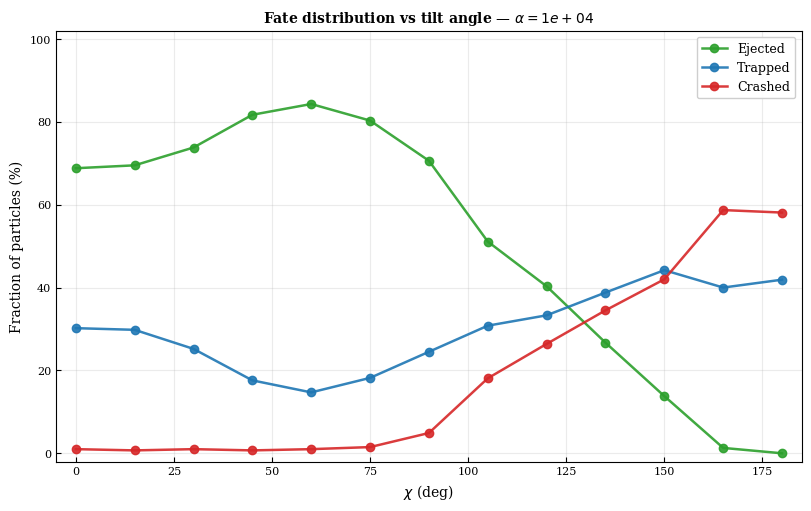

Salvo: fate_fractions_alpha1e+04.pdf


In [9]:
# =========================================================
# FIGURE 2 — FATE FRACTIONS vs ANGLE (um alpha)
# Ejected (verde), Trapped (azul), Crashed (vermelho)
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e4

FATE_COLORS = {"Ejected": "tab:green",
               "Trapped": "tab:blue",
               "Crashed": "tab:red"}

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

d = df[df["alpha"] == ALPHA_VAL].copy()
angles = sorted(d["angle_deg"].unique())

# ---------- Frações ----------
fracs = {f: [] for f in FATE_COLORS}
for ang in angles:
    dd = d[d.angle_deg == ang]
    N  = len(dd)
    for f in FATE_COLORS:
        fracs[f].append(100.0 * (dd.status == f).sum() / max(N, 1))

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

for f, col in FATE_COLORS.items():
    ax.plot(angles, fracs[f], 'o-', color=col, lw=1.8, ms=6,
            label=f, alpha=0.9)

ax.set_xlabel(r'$\chi$ (deg)')
ax.set_ylabel(r'Fraction of particles (%)')
ax.set_xlim(min(angles) - 5, max(angles) + 5)
ax.set_ylim(-2, 102)
ax.grid(True, alpha=0.25)
ax.legend(loc='best', fontsize=9, framealpha=0.95)
ax.set_title(rf'Fate distribution vs tilt angle — '
             rf'$\alpha = {ALPHA_VAL:.0e}$',
             fontweight='bold')

out = f'fate_fractions_alpha{ALPHA_VAL:.0e}.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

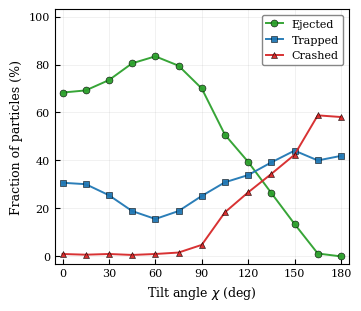

Salvo: fate_fractions_alpha1e+05.pdf  (figsize 3.5 × 3.0 in — single journal column)


In [17]:
# =========================================================
# FIGURE 2 (paper version) — FATE FRACTIONS vs TILT ANGLE
# Single α. Sized for a journal column.
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'figure.dpi': 100,
    'savefig.dpi': 300,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e5

FATE_COLORS  = {"Ejected": "#2ca02c",   # green
                "Trapped": "#1f77b4",   # blue
                "Crashed": "#d62728"}   # red
FATE_MARKERS = {"Ejected": "o",
                "Trapped": "s",
                "Crashed": "^"}

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

d = df[df["alpha"] == ALPHA_VAL].copy()
angles = sorted(d["angle_deg"].unique())

# ---------- Frações ----------
fracs = {f: [] for f in FATE_COLORS}
counts = []
for ang in angles:
    dd = d[d.angle_deg == ang]
    N  = len(dd)
    counts.append(N)
    for f in FATE_COLORS:
        fracs[f].append(100.0 * (dd.status == f).sum() / max(N, 1))

# ---------- Plot ----------
# Single-column width ≈ 3.4 in; two-column ≈ 7.0 in. Adjust as needed.
fig, ax = plt.subplots(figsize=(3.5, 3.0), constrained_layout=True)

for f in FATE_COLORS:
    ax.plot(angles, fracs[f],
            marker=FATE_MARKERS[f],
            color=FATE_COLORS[f],
            ls='-', lw=1.4, ms=5,
            markerfacecolor=FATE_COLORS[f],
            markeredgecolor='black',
            markeredgewidth=0.4,
            alpha=0.95, label=f)

ax.set_xlabel(r'Tilt angle $\chi$ (deg)', fontsize=9)
ax.set_ylabel(r'Fraction of particles (%)', fontsize=9)
ax.set_xlim(-5, 185)
ax.set_ylim(-3, 103)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.grid(True, alpha=0.25, lw=0.5)
#ax.axhline(0, color='k', lw=0.4, alpha=0.5)
#ax.axhline(100, color='k', lw=0.4, alpha=0.5)

# Legend inside, top-right corner
ax.legend(loc='upper right', framealpha=0.95,
          edgecolor='gray', handlelength=1.5)


out = f'fate_fractions_alpha{int(ALPHA_VAL):.0e}.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}  (figsize 3.5 × 3.0 in — single journal column)")

In [14]:
# =========================================================
# TABLE — fate fractions per angle for a single alpha
# =========================================================
import numpy as np
import pandas as pd

CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e4

df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

d = df[df["alpha"] == ALPHA_VAL].copy()
angles = sorted(d["angle_deg"].unique())

rows = []
for ang in angles:
    dd = d[d.angle_deg == ang]
    N  = len(dd)
    n_ej = int((dd.status == "Ejected").sum())
    n_tr = int((dd.status == "Trapped").sum())
    n_cr = int((dd.status == "Crashed").sum())
    rows.append({
        "χ (deg)": ang,
        "N total": N,
        "Ejected (n)": n_ej,
        "Ejected (%)": 100.0 * n_ej / max(N, 1),
        "Trapped (n)": n_tr,
        "Trapped (%)": 100.0 * n_tr / max(N, 1),
        "Crashed (n)": n_cr,
        "Crashed (%)": 100.0 * n_cr / max(N, 1),
    })

table = pd.DataFrame(rows)

# ---------- Console output (pretty) ----------
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)

print("=" * 100)
print(f"FATE FRACTIONS — alpha = {ALPHA_VAL:.0e}")
print("=" * 100)
print(table.to_string(index=False))
print()

# ---------- Totals row ----------
N_tot = table["N total"].sum()
ej_tot = table["Ejected (n)"].sum()
tr_tot = table["Trapped (n)"].sum()
cr_tot = table["Crashed (n)"].sum()
print(f"TOTAL: N = {N_tot}   "
      f"Ejected = {ej_tot} ({100*ej_tot/N_tot:.2f}%)   "
      f"Trapped = {tr_tot} ({100*tr_tot/N_tot:.2f}%)   "
      f"Crashed = {cr_tot} ({100*cr_tot/N_tot:.2f}%)")
print()

# ---------- LaTeX-ready output ----------
print("=" * 100)
print("LaTeX table (copy-paste into your manuscript):")
print("=" * 100)
print(r"\begin{table}[ht]")
print(r"\centering")
print(r"\caption{Fate fractions for $\alpha = "
      f"{int(ALPHA_VAL):.0e}$" + r"$ as a function of tilt angle.}")
print(r"\label{tab:fate_fractions}")
print(r"\begin{tabular}{r|rrr|rrr}")
print(r"\hline")
print(r"$\chi$ (deg) & \multicolumn{3}{c|}{Counts} & "
      r"\multicolumn{3}{c}{Fractions (\%)} \\")
print(r"             & Ej. & Tr. & Cr. & Ej. & Tr. & Cr. \\")
print(r"\hline")
for _, r in table.iterrows():
    print(f"{int(r['χ (deg)']):>3d} & "
          f"{int(r['Ejected (n)']):>3d} & "
          f"{int(r['Trapped (n)']):>3d} & "
          f"{int(r['Crashed (n)']):>3d} & "
          f"{r['Ejected (%)']:>5.1f} & "
          f"{r['Trapped (%)']:>5.1f} & "
          f"{r['Crashed (%)']:>5.1f} \\\\")
print(r"\hline")
print(f"Total & {ej_tot} & {tr_tot} & {cr_tot} & "
      f"{100*ej_tot/N_tot:.1f} & "
      f"{100*tr_tot/N_tot:.1f} & "
      f"{100*cr_tot/N_tot:.1f} \\\\")
print(r"\hline")
print(r"\end{tabular}")
print(r"\end{table}")

# ---------- Save as CSV for your records ----------
out_csv = f'fate_fractions_alpha{int(ALPHA_VAL):.0e}.csv'
table.to_csv(out_csv, index=False)
print(f"\nSaved: {out_csv}")

FATE FRACTIONS — alpha = 1e+04
 χ (deg)  N total  Ejected (n)  Ejected (%)  Trapped (n)  Trapped (%)  Crashed (n)  Crashed (%)
       0     1000          688        68.80          302        30.20           10         1.00
      15     1000          695        69.50          298        29.80            7         0.70
      30     1000          738        73.80          252        25.20           10         1.00
      45     1000          817        81.70          176        17.60            7         0.70
      60     1000          843        84.30          147        14.70           10         1.00
      75     1000          803        80.30          182        18.20           15         1.50
      90     1000          706        70.60          245        24.50           49         4.90
     105     1000          511        51.10          308        30.80          181        18.10
     120     1000          403        40.30          333        33.30          264        26.40
     135 

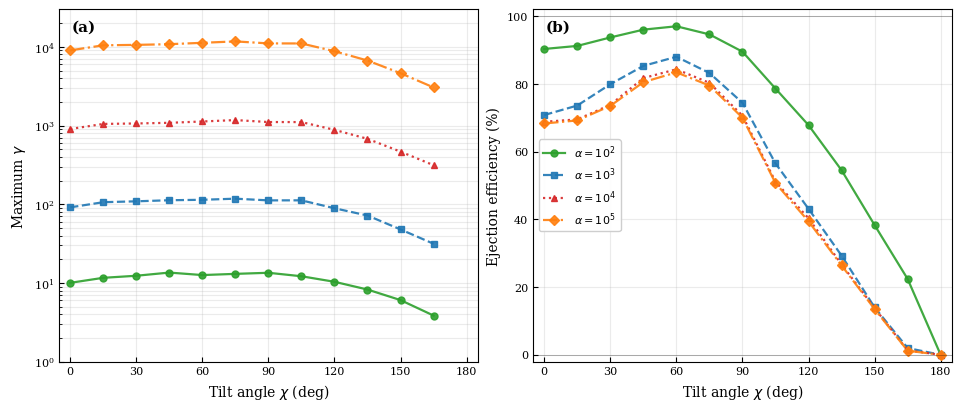

Salvo: maxgamma_and_efficiency_vs_angle.pdf  (one-row, two-column figure)


In [21]:
# =========================================================
# MERGED FIGURE — (a) max γ vs χ, (b) ejection efficiency vs χ
# One row, two columns. One curve per alpha in both panels.
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'figure.dpi': 100,
    'savefig.dpi': 300,
})

# ---------- Configuração ----------
CSV_FILE = "particles_all_runs.csv"

ALPHAS_TO_PLOT = [1e2, 1e3, 1e4,1e5]

# Status used for the "max γ" panel
# Options: "Ejected", "Crashed", "Trapped", "All"
STATUS_FOR_GMAX = "Ejected"

_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown',
               'tab:pink', 'tab:olive', 'tab:cyan']
_LS_POOL = ['-', '--', ':', '-.']
_MK_POOL = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

alphas_avail = sorted(df["alpha"].unique())
ALPHAS = [a for a in ALPHAS_TO_PLOT if a in alphas_avail]
if not ALPHAS:
    raise ValueError(f"No overlap with available alphas: {alphas_avail}")

angles = sorted(df["angle_deg"].unique())

# ---------- Compute both quantities ----------
gmax = {}
eff  = {}

for a in ALPHAS:
    d = df[df["alpha"] == a]
    g_row, e_row = [], []
    for ang in angles:
        dd = d[d.angle_deg == ang]
        N  = len(dd)

        # Ejection efficiency
        e_row.append(100.0 * (dd.status == "Ejected").sum() / max(N, 1))

        # Max gamma for the selected status
        if STATUS_FOR_GMAX != "All":
            dg = dd[dd.status == STATUS_FOR_GMAX]
        else:
            dg = dd
        g_row.append(dg.gamma_final.max() if len(dg) else np.nan)

    gmax[a] = g_row
    eff[a]  = e_row

# ---------- Plot ----------
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0),
                         constrained_layout=True,
                         sharex=True)

# =========================================================
# Panel (a) — Max gamma vs chi
# =========================================================
ax = axes[0]
for i, a in enumerate(ALPHAS):
    exp = int(round(np.log10(a)))
    lab = rf"$\alpha = 10^{{{exp}}}$" if 10**exp == a else rf"$\alpha = {a:g}$"
    ax.plot(angles, gmax[a],
            color=_COLOR_POOL[i % len(_COLOR_POOL)],
            ls=_LS_POOL[i % len(_LS_POOL)],
            marker=_MK_POOL[i % len(_MK_POOL)],
            lw=1.6, ms=5, alpha=0.9, label=lab)

ax.set_yscale('log')
ax.set_xlabel(r'Tilt angle $\chi$ (deg)', fontsize=10)
ax.set_ylabel(r'Maximum $\gamma$', fontsize=10)
ax.set_ylim(1, 3e4)
ax.set_xlim(min(angles) - 5, max(angles) + 5)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.grid(True, alpha=0.25, which='both')
ax.text(0.03, 0.97, '(a)', transform=ax.transAxes,
        ha='left', va='top', fontsize=11, fontweight='bold')

# =========================================================
# Panel (b) — Ejection efficiency vs chi
# =========================================================
ax = axes[1]
for i, a in enumerate(ALPHAS):
    exp = int(round(np.log10(a)))
    lab = rf"$\alpha = 10^{{{exp}}}$" if 10**exp == a else rf"$\alpha = {a:g}$"
    ax.plot(angles, eff[a],
            color=_COLOR_POOL[i % len(_COLOR_POOL)],
            ls=_LS_POOL[i % len(_LS_POOL)],
            marker=_MK_POOL[i % len(_MK_POOL)],
            lw=1.6, ms=5, alpha=0.9, label=lab)

ax.set_xlabel(r'Tilt angle $\chi$ (deg)', fontsize=10)
ax.set_ylabel(r'Ejection efficiency (%)', fontsize=10)
ax.set_xlim(min(angles) - 5, max(angles) + 5)
ax.set_ylim(-2, 102)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.grid(True, alpha=0.25)
ax.legend(loc='best', framealpha=0.95, fontsize=8)
ax.axhline(0, color='k', lw=0.4, alpha=0.5)
ax.axhline(100, color='k', lw=0.4, alpha=0.5)
# No legend here — panel (a)'s legend applies to both
ax.text(0.03, 0.97, '(b)', transform=ax.transAxes,
        ha='left', va='top', fontsize=11, fontweight='bold')

# ---------- Save ----------
out = 'maxgamma_and_efficiency_vs_angle.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}  (one-row, two-column figure)")

In [ ]:
# =========================================================
# FLATTENING DIAGNOSTIC
# For each (alpha, chi): compute log-width of the central
# 90%, 80%, 68% of the ejected gamma distribution.
# =========================================================
import numpy as np
import pandas as pd

CSV_FILE = "particles_all_runs.csv"
ALPHAS = [1e3, 1e4, 1e5]
ANGLES = list(range(0, 165, 15))   # up to 150

df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)
df_ej = df[df.status == "Ejected"]

def log_width(g, frac):
    """Width of the central `frac` of log10(g), in decades."""
    lg = np.log10(np.clip(g, 1.0, None))
    q_lo = np.quantile(lg, 0.5 - frac/2)
    q_hi = np.quantile(lg, 0.5 + frac/2)
    return q_hi - q_lo

rows = []
for a in ALPHAS:
    for ang in ANGLES:
        d = df_ej[(df_ej.alpha == a) & (df_ej.angle_deg == ang)]
        if len(d) < 20:
            continue
        g = d.gamma_final.values
        rows.append({
            "alpha": a,
            "chi": ang,
            "N": len(g),
            "w90": log_width(g, 0.90),
            "w80": log_width(g, 0.80),
            "w68": log_width(g, 0.68),
            "skew": np.log10(np.median(g)) - np.log10(np.mean(g)),
        })

tbl = pd.DataFrame(rows)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.3f}'.format)

print("=" * 90)
print("FLATTENING — logarithmic width of ejected gamma distribution")
print("=" * 90)
print(tbl.to_string(index=False))

print("\n" + "=" * 90)
print("WIDTH w90 as a function of chi, for each alpha")
print("=" * 90)
pivot = tbl.pivot(index="chi", columns="alpha", values="w90")
print(pivot.round(3).to_string())

# Save for the paper
tbl.to_csv("spectral_widths.csv", index=False)
print("\nSaved: spectral_widths.csv")

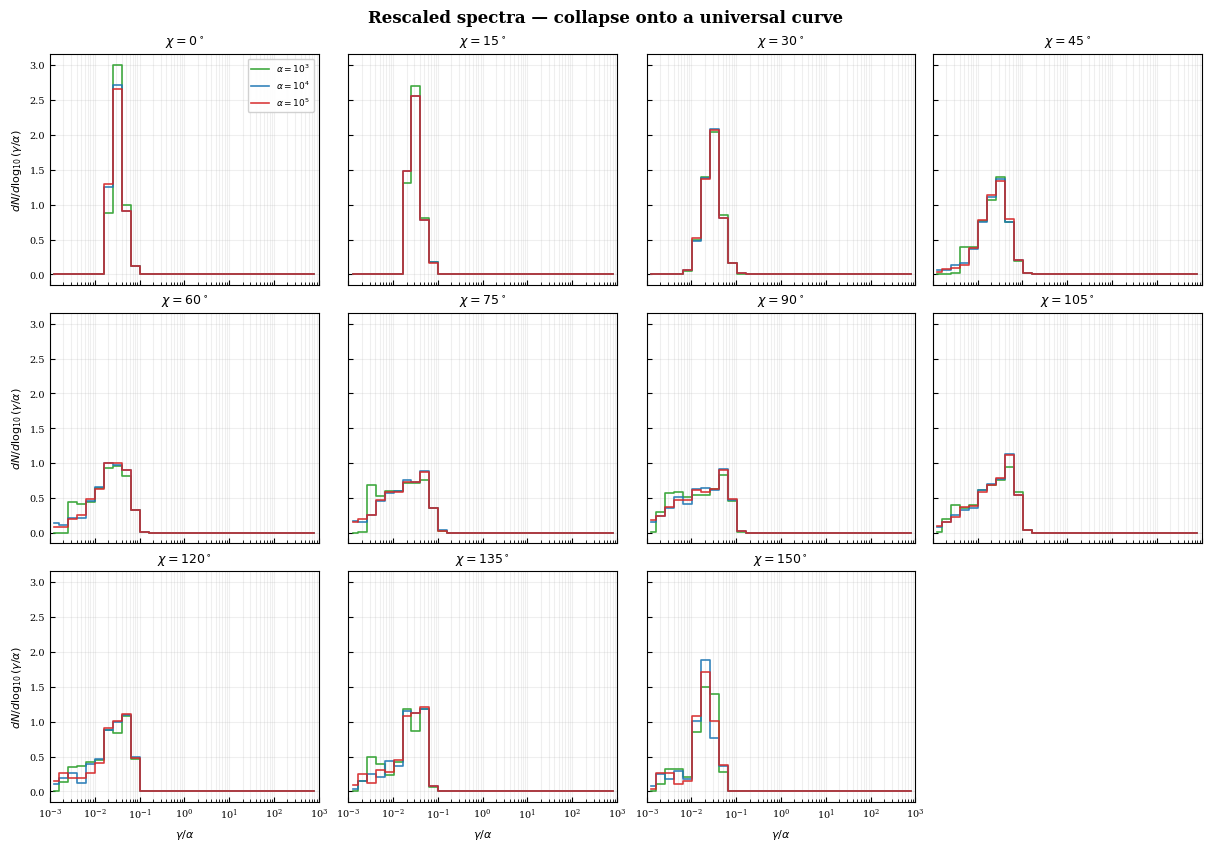

Salvo: spectra_rescaled.pdf


In [22]:
# =========================================================
# RESCALED SPECTRA — dN/dlog(gamma) vs gamma/alpha
# One panel per chi, three alphas overlaid.
# If the collapse is good, the physics is scale-invariant.
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7,
})

CSV_FILE = "particles_all_runs.csv"
ALPHAS = [1e3, 1e4,1e5]
ANGLES = [0, 15, 30, 45, 60, 75, 90, 105, 120, 135, 150]

_COLORS = {1e3: "tab:green", 1e4: "tab:blue", 1e5: "tab:red"}

df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)
df_ej = df[df.status == "Ejected"]

# Scaled binning: gamma/alpha in [1e-3, 1e3], log-spaced
N_BINS = 30
LO, HI = -3.0, 3.0
edges = np.linspace(LO, HI, N_BINS + 1)
centers = 10 ** (0.5 * (edges[:-1] + edges[1:]))

# =========================================================
# LAYOUT 3x4
# =========================================================
N_ROWS, N_COLS = 3, 4
fig, axes = plt.subplots(N_ROWS, N_COLS,
                         figsize=(3.0 * N_COLS, 2.8 * N_ROWS),
                         sharex=True, sharey=True,
                         constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    for a in ALPHAS:
        d = df_ej[(df_ej.alpha == a) & (df_ej.angle_deg == ang)]
        if len(d) < 10:
            continue
        scaled_g = d.gamma_final.values / a
        hist, _ = np.histogram(np.log10(scaled_g), bins=edges,
                               density=True)
        exp = int(round(np.log10(a)))
        ax.step(centers, hist, where='mid',
                color=_COLORS[a], lw=1.2, alpha=0.9,
                label=rf"$\alpha = 10^{{{exp}}}$")
    ax.set_xscale('log')
    ax.set_xlim(10**LO, 10**HI)
    ax.set_title(rf"$\chi = {ang}^\circ$", fontweight='bold')
    ax.grid(True, alpha=0.2, which='both')
    ax.tick_params(labelsize=7)
    if idx == 0:
        ax.legend(loc='upper right', fontsize=6.5,
                  framealpha=0.9)

# Hide unused panels
for idx in range(len(ANGLES), len(axes)):
    axes[idx].set_axis_off()

# Axis labels on the border only
for idx in range(len(ANGLES)):
    row, col = idx // N_COLS, idx % N_COLS
    if row == N_ROWS - 1:
        axes[idx].set_xlabel(r'$\gamma / \alpha$', fontsize=8)
    if col == 0:
        axes[idx].set_ylabel(r'$dN / d\log_{10}(\gamma/\alpha)$',
                             fontsize=8)

fig.suptitle(
    r'Rescaled spectra — collapse onto a universal curve',
    fontsize=12, fontweight='bold')

out = "spectra_rescaled.pdf"
plt.savefig(out, dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

In [ ]:
# =========================================================
# Ê·B̂ HEATMAP + LINHAS DE CAMPO — grade 4×4
# χ = 0°, 30°, ..., 360°  (13 ângulos no total)
# Ê·B̂ normalizado (−1 a +1), cores sólidas
# Eixo magnético com seta (apenas X > 0), cor preta
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch
from numba import njit

# ---------- Parâmetros ----------
R     = 1.0
c     = 1.0
B0    = 1.0
om    = 0.209
r_lc  = 1.0 / om

ANGLES = list(range(0, 361, 30))     # 0, 30, 60, ..., 360 (13 valores)
NGRID  = 250
R_MIN  = 1.02
R_MAX  = 1.3 * r_lc

DENSITY    = 0.6
LINEWIDTH  = 0.5
LINE_COLOR = 'gray'
ARROWSIZE  = 0.7

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
})

# ---------- Hankel ----------
@njit
def h1(z):
    if abs(z) < 1e-6:
        inv_z2 = 1.0 / (z * z)
        return -1j * inv_z2 - 0.5j + z / 3.0
    j1 = np.sin(z) / (z**2) - np.cos(z) / z
    y1 = -np.cos(z) / (z**2) - np.sin(z) / z
    return j1 + 1j * y1

@njit
def h2(z):
    if abs(z) < 1e-6:
        inv_z3 = 1.0 / (z * z * z)
        inv_z  = 1.0 / z
        return -3j * inv_z3 - 0.5j * inv_z
    j2 = (3.0 / (z**3) - 1.0 / z) * np.sin(z) - (3.0 / (z**2)) * np.cos(z)
    y2 = -(3.0 / (z**3) - 1.0 / z) * np.cos(z) - (3.0 / (z**2)) * np.sin(z)
    return j2 + 1j * y2

@njit
def h3(z):
    if abs(z) < 1e-6:
        inv_z4 = 1.0 / (z * z * z * z)
        return -15j * inv_z4
    j3 = (15.0 / (z**4) - 6.0 / (z**2)) * np.sin(z) - (15.0 / (z**3) - 1.0 / z) * np.cos(z)
    y3 = -(15.0 / (z**4) - 6.0 / (z**2)) * np.cos(z) - (15.0 / (z**3) - 1.0 / z) * np.sin(z)
    return j3 + 1j * y3

H_1_const  = h1(om * R)
H_2_const  = h2(om * R)
H_3_const  = h3(om * R)
D_H2_const = 3.0 * H_2_const - H_3_const * om * R

# ---------- Campo de Deutsch ----------
@njit
def EB_components(x, y, z_coord, t, X_tilt):
    r = np.sqrt(x**2 + y**2 + z_coord**2)
    if r < 1e-6:
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

    cos_theta = z_coord / r
    if cos_theta >  1.0: cos_theta =  1.0
    if cos_theta < -1.0: cos_theta = -1.0
    theta = np.arccos(cos_theta)
    phi   = np.arctan2(y, x)
    psi   = phi - om * t

    h_1 = h1(om * r); h_2 = h2(om * r); h_3 = h3(om * r)
    D_h1 = 2.0 * h_1 - h_2 * om * r
    D_h2 = 3.0 * h_2 - h_3 * om * r

    rot   = np.sin(X_tilt) * np.exp(1j * psi)
    cos_X = np.cos(X_tilt)

    geo_1r  = (R**3) / (r**3) * cos_theta * cos_X
    geo_2r  = (R / r) * (h_1 / H_1_const) * np.sin(theta)
    geo_1th = (R**3) / (r**3) * np.sin(theta) * cos_X
    geo_2th = ((R / r) * (D_h1 / H_1_const) +
               (R**2) / (r_lc**2) * (h_2 / D_H2_const)) * cos_theta
    geo_1phi = ((R / r) * (D_h1 / H_1_const) +
                (R**2) / (r_lc**2) * (h_2 / D_H2_const) * np.cos(2.0 * theta))

    B_r_im     = 2.0 * B0 * (geo_1r + geo_2r * rot)
    B_theta_im = B0 * (geo_1th + geo_2th * rot)
    B_phi_im   = 1j * B0 * (geo_1phi * rot)

    geo_1Er   = ((R**2) / (r**2) * cos_X) * (2.0 / 3.0 -
                (R**2) / (r**2) * (3.0 * cos_theta**2 - 1.0))
    geo_2Er   = (R / r) * (3.0 * np.sin(2.0 * theta) * h_2 / D_H2_const)
    geo_1Eth  = -(R**4) / (r**4) * np.sin(2.0 * theta) * cos_X
    geo_2Eth  = (R / r) * (D_h2 / D_H2_const) * np.cos(2.0 * theta) - h_1 / H_1_const
    geo_1Ephi = (R / r) * (D_h2 / D_H2_const) - h_1 / H_1_const

    E_r_im     = om * B0 * R / c * (geo_1Er + geo_2Er * rot)
    E_theta_im = om * B0 * R / c * (geo_1Eth + geo_2Eth * rot)
    E_phi_im   = 1j * om * B0 * R / c * (geo_1Ephi * cos_theta * rot)

    Br = np.real(B_r_im); Btheta = np.real(B_theta_im); Bphi = np.real(B_phi_im)
    Er = np.real(E_r_im); Etheta = np.real(E_theta_im); Ephi = np.real(E_phi_im)

    st, ct = np.sin(theta), np.cos(theta)
    sp, cp = np.sin(phi),   np.cos(phi)

    Bx = Br*st*cp + Btheta*ct*cp - Bphi*sp
    By = Br*st*sp + Btheta*ct*sp + Bphi*cp
    Bz = Br*ct    - Btheta*st

    Ex = Er*st*cp + Etheta*ct*cp - Ephi*sp
    Ey = Er*st*sp + Etheta*ct*sp + Ephi*cp
    Ez = Er*ct    - Etheta*st

    return Ex, Ey, Ez, Bx, By, Bz

# ---------- Grid ----------
@njit
def compute_grid_XZ(x_vals, z_vals, t, X_tilt, r_min, r_max):
    N = len(x_vals)
    EBn_grid = np.full((N, N), np.nan)
    Bx_grid  = np.zeros((N, N))
    Bz_grid  = np.zeros((N, N))

    for i in range(N):
        for j in range(N):
            x = x_vals[j]
            z = z_vals[i]
            r = np.sqrt(x*x + z*z)
            if r < r_min or r > r_max:
                continue
            ex, ey, ez, bx, by, bz = EB_components(x, 0.0, z, t, X_tilt)

            nE = np.sqrt(ex*ex + ey*ey + ez*ez)
            nB = np.sqrt(bx*bx + by*by + bz*bz)
            if nE > 0 and nB > 0:
                EBn_grid[i, j] = (ex*bx + ey*by + ez*bz) / (nE * nB)

            Bx_grid[i, j] = bx
            Bz_grid[i, j] = bz
    return EBn_grid, Bx_grid, Bz_grid

# =========================================================
# PLOT — 4×4 grid, 13 angles + 3 empty panels
# =========================================================
N_ROWS = 4
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(16, 16),
                          constrained_layout=True)
axes = axes.ravel()

x_arr = np.linspace(-R_MAX, R_MAX, NGRID)
z_arr = np.linspace(-R_MAX, R_MAX, NGRID)
X, Z = np.meshgrid(x_arr, z_arr)

norm = Normalize(vmin=-1, vmax=1)

for k, ang in enumerate(ANGLES):
    ax = axes[k]
    Xt = np.radians(ang)

    EBn, Bx, Bz = compute_grid_XZ(x_arr, z_arr, 0.0, Xt, R_MIN, R_MAX)

    im = ax.pcolormesh(X, Z, EBn, shading='gouraud',
                       cmap='RdBu_r', norm=norm,
                       rasterized=True, zorder=1)

    ax.streamplot(x_arr, z_arr, Bx, Bz,
                  color=LINE_COLOR, linewidth=LINEWIDTH,
                  density=DENSITY, arrowsize=ARROWSIZE,
                  zorder=4, broken_streamlines=False)

    ax.add_patch(plt.Circle((0, 0), R, color='black', zorder=5))

    L = R_MAX * 0.9
    dx = L * np.sin(Xt)
    dz = L * np.cos(Xt)
    arrow = FancyArrowPatch(
        (0, 0), (dx, dz),
        arrowstyle='-|>', color='black', lw=1.8,
        mutation_scale=14, shrinkA=0, shrinkB=0, zorder=6,
    )
    ax.add_patch(arrow)

    ax.set_aspect('equal')
    ax.set_xlim(-R_MAX, R_MAX)
    ax.set_ylim(-R_MAX, R_MAX)
    ax.set_xlabel('X (R)')
    if k % N_COLS == 0:
        ax.set_ylabel('Z (R)')
    ax.set_title(rf'$\chi = {ang}^\circ$', fontweight='bold')
    ax.grid(True, alpha=0.15, zorder=0)
    ax.tick_params(labelsize=8)

# Hide the leftover panels (13 angles fill 13 slots; 3 panels remain empty)
for idx in range(len(ANGLES), len(axes)):
    axes[idx].set_axis_off()

# Colorbar
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(),
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'$\hat{E} \cdot \hat{B}$', fontsize=10)

fig.suptitle(r'$\mathbf{E \cdot B}$ — tilt angles $0^\circ$ to $360^\circ$ in $30^\circ$ steps',
             fontsize=14, fontweight='bold')

plt.show()
print(f"Plotted {len(ANGLES)} angles: {ANGLES}")

In [ ]:
# =========================================================
# MERGED — Ê·B̂ HEATMAP + FIELD LINES + INITIAL POSITIONS
# 3×4 grid, χ = 0°, 15°, ..., 165°
# Black dots = initial positions of ejected particles (α = 1e5)
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch
from numba import njit
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# =========================================================
# PARAMETERS
# =========================================================
R     = 1.0
c     = 1.0
B0    = 1.0
om    = 0.209
r_lc  = 1.0 / om

# Angles: 12 values, matching Block 1
ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

# Field grid
NGRID  = 220
R_MIN  = 1.02
R_MAX  = 1.3 * r_lc

# Streamplot styling
DENSITY    = 0.6
LINEWIDTH  = 0.4
LINE_COLOR = 'gray'
ARROWSIZE  = 0.6

# CSV / particle filter
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 1e5
STATUS    = "Ejected"

# Marker styling for particles
PARTICLE_SIZE  = 8
PARTICLE_COLOR = 'black'
PARTICLE_ALPHA = 0.55

# Zoom for the panel extent
ZOOM_LIM = r_lc * 1.15

# =========================================================
# HANKEL FUNCTIONS
# =========================================================
@njit
def h1(z):
    if abs(z) < 1e-6:
        inv_z2 = 1.0 / (z * z)
        return -1j * inv_z2 - 0.5j + z / 3.0
    j1 = np.sin(z) / (z**2) - np.cos(z) / z
    y1 = -np.cos(z) / (z**2) - np.sin(z) / z
    return j1 + 1j * y1

@njit
def h2(z):
    if abs(z) < 1e-6:
        inv_z3 = 1.0 / (z * z * z)
        inv_z  = 1.0 / z
        return -3j * inv_z3 - 0.5j * inv_z
    j2 = (3.0 / (z**3) - 1.0 / z) * np.sin(z) - (3.0 / (z**2)) * np.cos(z)
    y2 = -(3.0 / (z**3) - 1.0 / z) * np.cos(z) - (3.0 / (z**2)) * np.sin(z)
    return j2 + 1j * y2

@njit
def h3(z):
    if abs(z) < 1e-6:
        inv_z4 = 1.0 / (z * z * z * z)
        return -15j * inv_z4
    j3 = (15.0 / (z**4) - 6.0 / (z**2)) * np.sin(z) - (15.0 / (z**3) - 1.0 / z) * np.cos(z)
    y3 = -(15.0 / (z**4) - 6.0 / (z**2)) * np.cos(z) - (15.0 / (z**3) - 1.0 / z) * np.sin(z)
    return j3 + 1j * y3

H_1_const  = h1(om * R)
H_2_const  = h2(om * R)
H_3_const  = h3(om * R)
D_H2_const = 3.0 * H_2_const - H_3_const * om * R

# =========================================================
# DEUTSCH FIELD
# =========================================================
@njit
def EB_components(x, y, z_coord, t, X_tilt):
    r = np.sqrt(x**2 + y**2 + z_coord**2)
    if r < 1e-6:
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

    cos_theta = z_coord / r
    if cos_theta >  1.0: cos_theta =  1.0
    if cos_theta < -1.0: cos_theta = -1.0
    theta = np.arccos(cos_theta)
    phi   = np.arctan2(y, x)
    psi   = phi - om * t

    h_1 = h1(om * r); h_2 = h2(om * r); h_3 = h3(om * r)
    D_h1 = 2.0 * h_1 - h_2 * om * r
    D_h2 = 3.0 * h_2 - h_3 * om * r

    rot   = np.sin(X_tilt) * np.exp(1j * psi)
    cos_X = np.cos(X_tilt)

    geo_1r  = (R**3) / (r**3) * cos_theta * cos_X
    geo_2r  = (R / r) * (h_1 / H_1_const) * np.sin(theta)
    geo_1th = (R**3) / (r**3) * np.sin(theta) * cos_X
    geo_2th = ((R / r) * (D_h1 / H_1_const) +
               (R**2) / (r_lc**2) * (h_2 / D_H2_const)) * cos_theta
    geo_1phi = ((R / r) * (D_h1 / H_1_const) +
                (R**2) / (r_lc**2) * (h_2 / D_H2_const) * np.cos(2.0 * theta))

    B_r_im     = 2.0 * B0 * (geo_1r + geo_2r * rot)
    B_theta_im = B0 * (geo_1th + geo_2th * rot)
    B_phi_im   = 1j * B0 * (geo_1phi * rot)

    geo_1Er   = ((R**2) / (r**2) * cos_X) * (2.0 / 3.0 -
                (R**2) / (r**2) * (3.0 * cos_theta**2 - 1.0))
    geo_2Er   = (R / r) * (3.0 * np.sin(2.0 * theta) * h_2 / D_H2_const)
    geo_1Eth  = -(R**4) / (r**4) * np.sin(2.0 * theta) * cos_X
    geo_2Eth  = (R / r) * (D_h2 / D_H2_const) * np.cos(2.0 * theta) - h_1 / H_1_const
    geo_1Ephi = (R / r) * (D_h2 / D_H2_const) - h_1 / H_1_const

    E_r_im     = om * B0 * R / c * (geo_1Er + geo_2Er * rot)
    E_theta_im = om * B0 * R / c * (geo_1Eth + geo_2Eth * rot)
    E_phi_im   = 1j * om * B0 * R / c * (geo_1Ephi * cos_theta * rot)

    Br = np.real(B_r_im); Btheta = np.real(B_theta_im); Bphi = np.real(B_phi_im)
    Er = np.real(E_r_im); Etheta = np.real(E_theta_im); Ephi = np.real(E_phi_im)

    st, ct = np.sin(theta), np.cos(theta)
    sp, cp = np.sin(phi),   np.cos(phi)

    Bx = Br*st*cp + Btheta*ct*cp - Bphi*sp
    By = Br*st*sp + Btheta*ct*sp + Bphi*cp
    Bz = Br*ct    - Btheta*st

    Ex = Er*st*cp + Etheta*ct*cp - Ephi*sp
    Ey = Er*st*sp + Etheta*ct*sp + Ephi*cp
    Ez = Er*ct    - Etheta*st

    return Ex, Ey, Ez, Bx, By, Bz

@njit
def compute_grid_XZ(x_vals, z_vals, t, X_tilt, r_min, r_max):
    N = len(x_vals)
    EBn_grid = np.full((N, N), np.nan)
    Bx_grid  = np.zeros((N, N))
    Bz_grid  = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            x = x_vals[j]
            z = z_vals[i]
            r = np.sqrt(x*x + z*z)
            if r < r_min or r > r_max:
                continue
            ex, ey, ez, bx, by, bz = EB_components(x, 0.0, z, t, X_tilt)
            nE = np.sqrt(ex*ex + ey*ey + ez*ez)
            nB = np.sqrt(bx*bx + by*by + bz*bz)
            if nE > 0 and nB > 0:
                EBn_grid[i, j] = (ex*bx + ey*by + ez*bz) / (nE * nB)
            Bx_grid[i, j] = bx
            Bz_grid[i, j] = bz
    return EBn_grid, Bx_grid, Bz_grid

# =========================================================
# LOAD PARTICLES
# =========================================================
if not os.path.isfile(CSV_FILE):
    raise FileNotFoundError(f"{CSV_FILE} not found.")

df_all = pd.read_csv(CSV_FILE)
if "gamma" in df_all.columns and "gamma_final" not in df_all.columns:
    df_all = df_all.rename(columns={"gamma": "gamma_final"})
df_all["angle_deg"] = df_all["angle_deg"].round().astype(int)

alphas_avail = sorted(df_all["alpha"].unique())
if ALPHA_VAL not in alphas_avail:
    print(f"[WARN] alpha={ALPHA_VAL} not in CSV. Using closest.")
    ALPHA_VAL = float(alphas_avail[
        np.argmin(np.abs(np.array(alphas_avail) - ALPHA_VAL))])

df = df_all[(df_all["alpha"] == ALPHA_VAL)
            & (df_all["status"] == STATUS)].copy()
print(f"Loaded {len(df)} {STATUS} particles for alpha = {ALPHA_VAL:.0e}")

# =========================================================
# PLOT — 3×4, one panel per angle
# =========================================================
N_ROWS, N_COLS = 3, 4
fig, axes = plt.subplots(N_ROWS, N_COLS,
                         figsize=(3.6 * N_COLS, 3.4 * N_ROWS),
                         constrained_layout=True)
axes = axes.ravel()

# Field grid (only need one, reused)
x_arr = np.linspace(-ZOOM_LIM, ZOOM_LIM, NGRID)
z_arr = np.linspace(-ZOOM_LIM, ZOOM_LIM, NGRID)
X, Z  = np.meshgrid(x_arr, z_arr)

norm = Normalize(vmin=-1, vmax=1)
theta_circ = np.linspace(0, 2*np.pi, 400)

for k, ang in enumerate(ANGLES):
    ax = axes[k]
    Xt = np.radians(ang)

    # --- Ê·B̂ heatmap and field lines (computed within the zoomed region) ---
    EBn, Bx, Bz = compute_grid_XZ(x_arr, z_arr, 0.0, Xt,
                                   R_MIN, ZOOM_LIM)

    ax.pcolormesh(X, Z, EBn, shading='gouraud',
                  cmap='RdBu_r', norm=norm,
                  rasterized=True, zorder=1)

    ax.streamplot(x_arr, z_arr, Bx, Bz,
                  color=LINE_COLOR, linewidth=LINEWIDTH,
                  density=DENSITY, arrowsize=ARROWSIZE,
                  zorder=2, broken_streamlines=False)

    # --- Star ---
    ax.add_patch(plt.Circle((0, 0), R, color='black', zorder=6))

    # --- Light-cylinder lines ---
    ax.axvline( r_lc, color='black', ls='--', lw=0.7,
               alpha=0.6, zorder=3)
    ax.axvline(-r_lc, color='black', ls='--', lw=0.7,
               alpha=0.6, zorder=3)

    # --- Magnetic axis arrow (X > 0 only) ---
    L = ZOOM_LIM * 0.9
    dx = L * np.sin(Xt)
    dz = L * np.cos(Xt)
    arrow = FancyArrowPatch(
        (0, 0), (dx, dz),
        arrowstyle='-|>', color='black', lw=1.4,
        mutation_scale=10, shrinkA=0, shrinkB=0, zorder=7,
    )
    ax.add_patch(arrow)

    # --- Ejected particles as black dots ---
    d = df[df["angle_deg"] == ang]
    if len(d) > 0:
        ax.scatter(d.x0.values, d.z0.values,
                   s=PARTICLE_SIZE, c=PARTICLE_COLOR,
                   alpha=PARTICLE_ALPHA, edgecolors='none',
                   zorder=5)
        N = len(d)
    else:
        N = 0

    # --- Panel cosmetics ---
    ax.set_aspect('equal')
    ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_xlabel(r'$X_0$ (R)', fontsize=8)
    if k % N_COLS == 0:
        ax.set_ylabel(r'$Z_0$ (R)', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {N})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.15, zorder=0)
    ax.tick_params(labelsize=7)

# --- Colorbar ---
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(),
                    location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'$\hat{E} \cdot \hat{B}$', fontsize=9)

fig.suptitle(
    r'$\mathbf{E \cdot B}$ background, field lines, and initial '
    r'positions of ejected particles — '
    rf'$\alpha = {ALPHA_VAL:.0e}$',
    fontsize=12, fontweight='bold')

out = f'EBn_fieldlines_particles_alpha{ALPHA_VAL:.0e}.pdf'
plt.savefig(out, dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

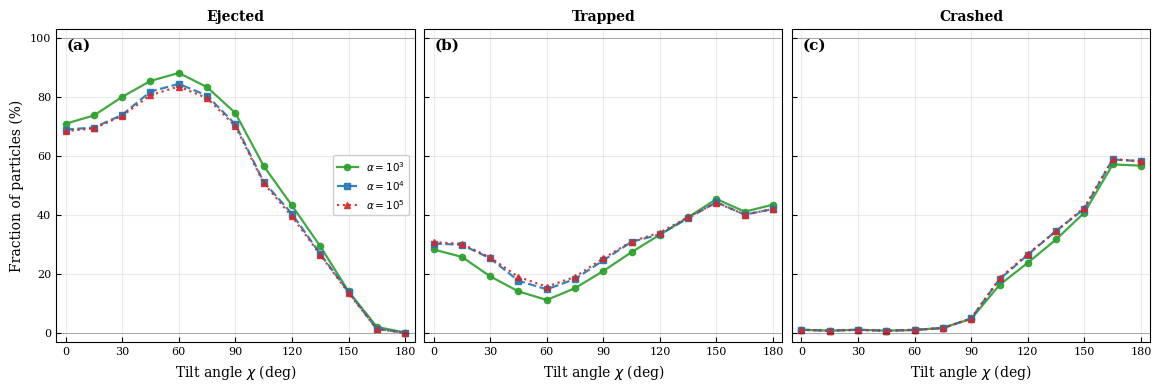

Salvo: fate_efficiencies_1x3.pdf


In [28]:
# =========================================================
# FATE EFFICIENCIES — 1 row, 3 columns
# (a) Ejected, (b) Trapped, (c) Crashed
# One curve per alpha in every panel.
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif',
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'figure.dpi': 100,
    'savefig.dpi': 300,
})

# ---------- Configuration ----------
CSV_FILE = "particles_all_runs.csv"
ALPHAS_TO_PLOT = [1e3, 1e4, 1e5]

_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown',
               'tab:pink', 'tab:olive', 'tab:cyan']
_LS_POOL = ['-', '--', ':', '-.']
_MK_POOL = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']

# ---------- Load ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

alphas_avail = sorted(df["alpha"].unique())
ALPHAS = [a for a in ALPHAS_TO_PLOT if a in alphas_avail]
if not ALPHAS:
    raise ValueError(f"No overlap with available alphas: {alphas_avail}")

angles = sorted(df["angle_deg"].unique())

# ---------- Compute the three efficiencies ----------
STATUSES = ["Ejected", "Trapped", "Crashed"]
fracs = {s: {a: [] for a in ALPHAS} for s in STATUSES}

for a in ALPHAS:
    d = df[df["alpha"] == a]
    for ang in angles:
        dd = d[d.angle_deg == ang]
        N = len(dd)
        for s in STATUSES:
            fracs[s][a].append(100.0 * (dd.status == s).sum() / max(N, 1))

# ---------- Plot: 1 row x 3 columns ----------
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8),
                         constrained_layout=True,
                         sharex=True, sharey=True)

for k, s in enumerate(STATUSES):
    ax = axes[k]
    for i, a in enumerate(ALPHAS):
        exp = int(round(np.log10(a)))
        lab = (rf"$\alpha = 10^{{{exp}}}$" if 10**exp == a
               else rf"$\alpha = {a:g}$")
        ax.plot(angles, fracs[s][a],
                color=_COLOR_POOL[i % len(_COLOR_POOL)],
                ls=_LS_POOL[i % len(_LS_POOL)],
                marker=_MK_POOL[i % len(_MK_POOL)],
                lw=1.6, ms=4.5, alpha=0.9, label=lab)
    ax.set_xlabel(r'Tilt angle $\chi$ (deg)', fontsize=10)
    ax.set_xlim(min(angles) - 5, max(angles) + 5)
    ax.set_ylim(-3, 103)
    ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
    ax.grid(True, alpha=0.25)
    ax.axhline(0, color='k', lw=0.4, alpha=0.5)
    ax.axhline(100, color='k', lw=0.4, alpha=0.5)
    # Panel label
    ax.text(0.03, 0.97, f"({chr(ord('a')+k)})", transform=ax.transAxes,
            ha='left', va='top', fontsize=11, fontweight='bold')
    # Panel subtitle
    ax.set_title(s, fontsize=10, fontweight='bold')

# Only the leftmost panel gets the y-axis label
axes[0].set_ylabel(r'Fraction of particles (%)', fontsize=10)

# Legend only in the first panel
axes[0].legend(loc='best', framealpha=0.95, fontsize=7.5)

out = 'fate_efficiencies_1x3.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}")

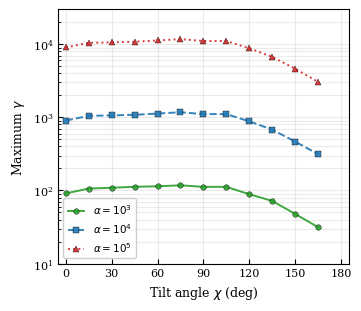

Salvo: maxgamma_vs_angle_column.pdf  (figsize 3.5 x 3.0 in — single journal column)


In [27]:
# =========================================================
# STANDALONE MAX-GAMMA PANEL — single journal column
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 7.5,
    'figure.dpi': 100,
    'savefig.dpi': 300,
})

# ---------- Configuration ----------
CSV_FILE = "particles_all_runs.csv"
ALPHAS_TO_PLOT = [1e3, 1e4, 1e5]
STATUS_FOR_GMAX = "Ejected"   # "Ejected", "Crashed", "Trapped", "All"

_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown']
_LS_POOL = ['-', '--', ':', '-.']
_MK_POOL = ['o', 's', '^', 'D', 'v', 'P']

# ---------- Load ----------
df = pd.read_csv(CSV_FILE)
if "gamma" in df.columns and "gamma_final" not in df.columns:
    df = df.rename(columns={"gamma": "gamma_final"})
df["angle_deg"] = df["angle_deg"].round().astype(int)

alphas_avail = sorted(df["alpha"].unique())
ALPHAS = [a for a in ALPHAS_TO_PLOT if a in alphas_avail]
if not ALPHAS:
    raise ValueError(f"No overlap with available alphas: {alphas_avail}")

angles = sorted(df["angle_deg"].unique())

# ---------- Max gamma per angle ----------
gmax = {}
for a in ALPHAS:
    d = df[df["alpha"] == a]
    row = []
    for ang in angles:
        dd = d[d.angle_deg == ang]
        if STATUS_FOR_GMAX != "All":
            dd = dd[dd.status == STATUS_FOR_GMAX]
        row.append(dd.gamma_final.max() if len(dd) else np.nan)
    gmax[a] = row

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(3.5, 3.0), constrained_layout=True)

for i, a in enumerate(ALPHAS):
    exp = int(round(np.log10(a)))
    lab = (rf"$\alpha = 10^{{{exp}}}$" if 10**exp == a
           else rf"$\alpha = {a:g}$")
    ax.plot(angles, gmax[a],
            color=_COLOR_POOL[i % len(_COLOR_POOL)],
            ls=_LS_POOL[i % len(_LS_POOL)],
            marker=_MK_POOL[i % len(_MK_POOL)],
            lw=1.4, ms=4, alpha=0.9, label=lab,
            markeredgecolor='black', markeredgewidth=0.3)

ax.set_yscale('log')
ax.set_xlabel(r'Tilt angle $\chi$ (deg)', fontsize=9)
ax.set_ylabel(r'Maximum $\gamma$', fontsize=9)
ax.set_xlim(-5, 185)
ax.set_ylim(10, 3e4)
ax.set_xticks([0, 30, 60, 90, 120, 150, 180])
ax.grid(True, alpha=0.25, which='both')
ax.legend(loc='lower left', framealpha=0.95,
          handlelength=1.6, borderpad=0.4)

out = 'maxgamma_vs_angle_column.pdf'
plt.savefig(out, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out}  (figsize 3.5 x 3.0 in — single journal column)")